# Clustering with Outlier Removal Implementation

In [ ]:
import pandas as pd
import numpy as np

from .utils.data_utils import *
from .utils.cor_utils import *
from .utils.evaluation import *


COR Algorithm

In [ ]:
def COR(X: pd.DataFrame, K: int, o:int, r:int, n_init: int = 1, additional_bp: list = None, verbose: bool = False)-> tuple[np.ndarray, float, dict]:
    """
    Main function; runs the COR algorithm as presented in the paper. In this version, if the dataset contains categorical columns,
    it is left possible to use them as additional basic partitions. 
    
    Inputs:
    -   X: the data matrix
    -   K: the number of clusters
    -   o: the number of outliers
    -   r: the number of basic partitions generated by K-means
    -   n_init: the number of times we run K-means--
    -   additional_bp: the list of extra basic partitions 
    -   verbose: a boolean that, if set to True, enables a log of every iteration. False by default
    
    Outputs:
    -   The final partition in the form of a vector of labels
    -   The minimum objective value obtained
    -   Some run statistics
    """
    #setup
    basic_partitions_labels = generate_basic_partitions(X, r, k_max=2*K)
    if additional_bp:
        basic_partitions_labels += additional_bp #categorical columns are turned into basic partitions

    B, tilde_B = build_binary_matrices(basic_partitions_labels)
    BB = np.hstack([B,tilde_B])
    best_obj_value = np.inf
    best_labels = None
    run_statistics = {"iterations" : [], "labels" : [], "obj_values": []}


    for i in range(n_init): #we run K-means-- n_init times#
        centroids = generate_centroids(BB, K)
        iter = 0  
        prev_obj_value = np.inf  


        while (iter<1000):
            iter+= 1 
            c_labels, min_distances= compute_kl_distances(BB, centroids= centroids)
            outlier_candidates = extract_outliers(min_distances, o) 
            c_labels[outlier_candidates] = -1
            centroids = update_centroids(BB, c_labels,centroids)
            obj_value = compute_holoentropy(BB, c_labels, centroids)

            if(prev_obj_value < obj_value):
                print("Objective value increased: force-quitted.")

                break
            elif (prev_obj_value-obj_value<= 1e-10): #the while cycle terminates once the marginal difference gets too small
                break

            if verbose:
                print(f"Run: {i}. Iteration: {iter}; objective value: {obj_value}\n")
            prev_obj_value = obj_value


        if obj_value < best_obj_value:
            best_obj_value = obj_value
            best_labels = c_labels

        run_statistics["iterations"].append(iter)
        run_statistics["labels"].append(c_labels)
        run_statistics["obj_values"].append(obj_value)

    return best_labels, best_obj_value, run_statistics

## Datasets and tests

### Forestfires


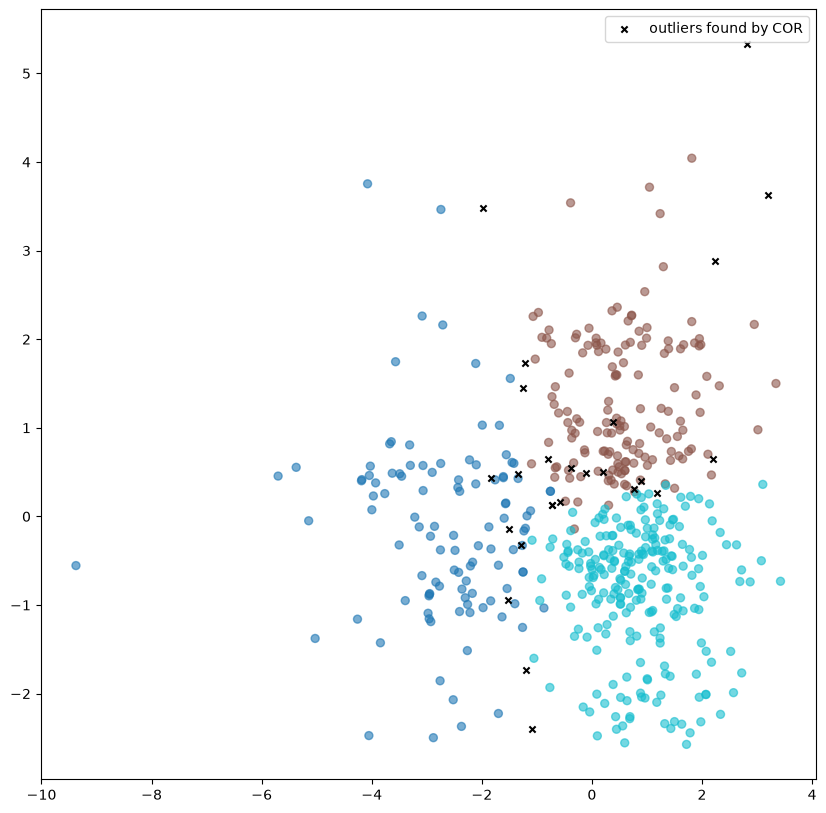

In [42]:
fires = pd.read_csv("datasets/forestfires.csv")
# fires.info()
# fires.describe()
# plot_correlation(fires)

#---------------------------------------------------

fires, add_parts_fires = make_categoric_partitions(fires)
fires = standardise(fires)
cor_labels_fires,fires_obj, fires_stats = COR(fires, 3, int(len(fires)*0.05), 200,n_init=10, additional_bp=add_parts_fires)

PCA_scatter_plot(fires, cor_labels_fires)


### Wine

iteration: 0; objective value: 307411.374268927

iteration: 1; objective value: 285660.66528603935

iteration: 2; objective value: 260778.45026225626

iteration: 3; objective value: 240786.15779343108

iteration: 4; objective value: 239920.01264538208

iteration: 5; objective value: 239646.49154330592



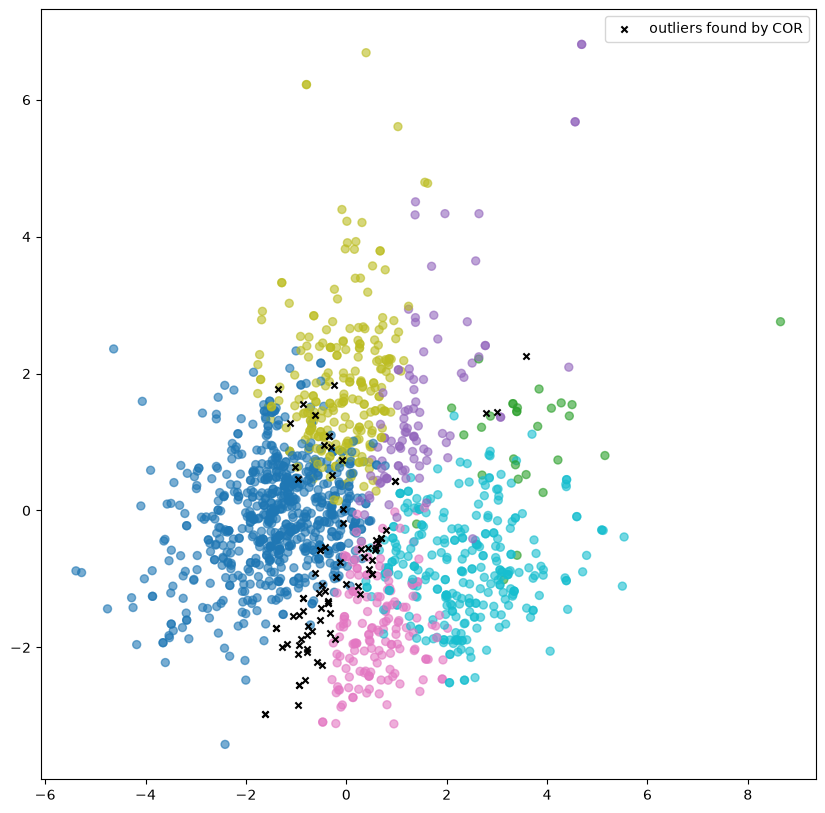

In [ ]:
red_wine_quality = pd.read_csv("datasets/wine+quality/winequality-red.csv",delimiter=";")
# red_wine_quality.info()
# red_wine_quality.describe()
target = red_wine_quality["quality"].to_numpy()
red_wine_quality.drop("quality",axis=1, inplace=True)
# plot_correlation(red_wine_quality)

# -----------------------------------------------------

red_wine_quality = standardise(red_wine_quality)
cor_labels_red_wine, _, _ = COR(red_wine_quality,len(np.unique(target)),int(len(red_wine_quality)*0.05), 100)

PCA_scatter_plot(red_wine_quality, cor_labels_red_wine)

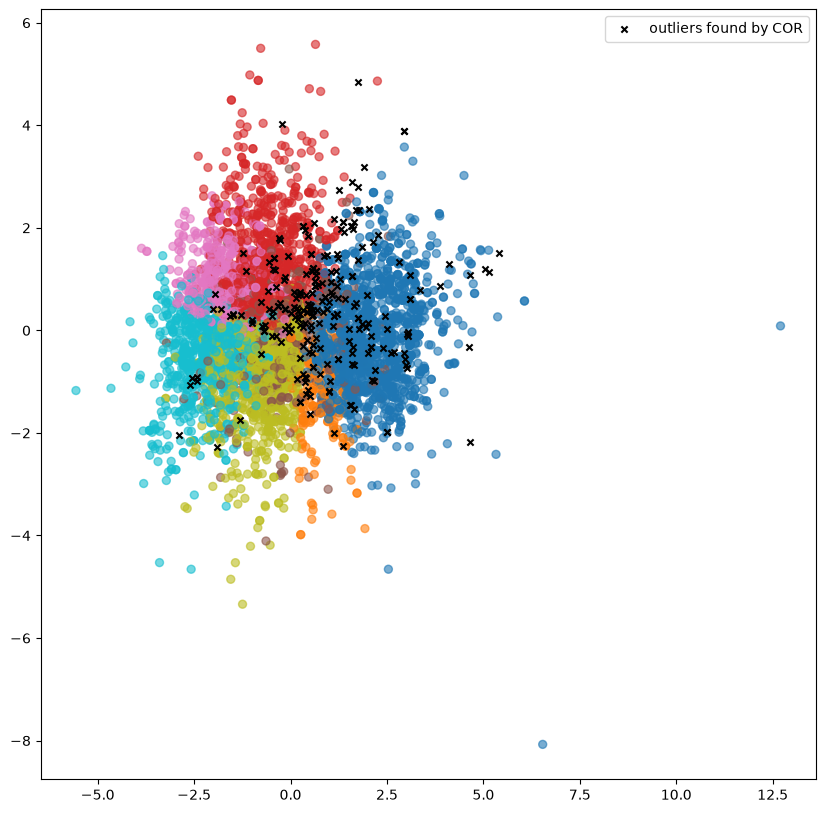

In [38]:
white_wine_quality = pd.read_csv("datasets/wine+quality/winequality-white.csv",delimiter=";")
# white_wine_quality.info()
# white_wine_quality.describe()
target = white_wine_quality["quality"].to_numpy()
white_wine_quality.drop("quality",axis = 1, inplace = True)
#plot_correlation(white_wine_quality)

# --------------------------------------------------------

white_wine_quality = standardise(white_wine_quality)

cor_labels_white_wine, _, _ = COR(white_wine_quality,len(np.unique(target)),int(len(white_wine_quality)*0.05), 200)
PCA_scatter_plot(white_wine_quality,labels=cor_labels_white_wine)

### Statlog Shuttle

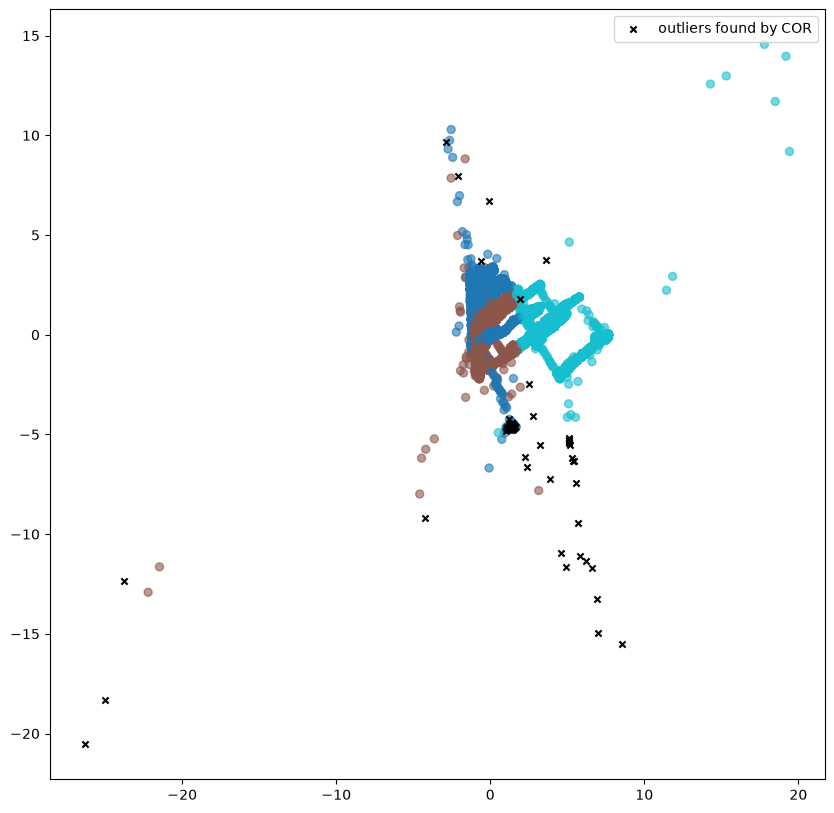

In [ ]:
header = ["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8", "A9", "Class"]
shuttle_train = pd.read_csv("datasets/statlog+shuttle/train_shuttle.csv", sep = ",",header=None, names=header)
shuttle_test  = pd.read_csv("datasets/statlog+shuttle/test_shuttle.csv", sep = ",",header=None, names = header)
shuttle = pd.concat([shuttle_train,shuttle_test], ignore_index=True)
# shuttle.info()
# shuttle.describe()
shuttle_target  = shuttle.Class
shuttle.drop("Class",axis = 1, inplace = True)
shuttle = standardise(shuttle)
# plot_correlation(shuttle)

# -------------------------------------------------

outlier_indexes = shuttle[shuttle_target.isin([2, 3, 6, 7])].index   # 2,3,6,7 are the classes considered outlier set by the paper; found with value_counts()
true_outliers_shuttle = np.zeros(len(shuttle), dtype=bool)
true_outliers_shuttle[outlier_indexes] = True


cor_labels_shuttle,shuttle_obj, stats = COR(shuttle, K = 3, o=len(true_outliers_shuttle[true_outliers_shuttle==True]),r = 300,n_init= 3)
PCA_scatter_plot(shuttle,cor_labels_shuttle)

## Performances Evaluation

In [29]:
evaluate_COR(cor_labels_shuttle,shuttle_target,true_outliers_shuttle)

{'NMI': 0.3249699432940875,
 'R_n': 0.4523806407857989,
 'Jaccard': 0.014553014553014554,
 'F-measure': 0.028688524590163935}